# Module 11 — Survival Analysis and Censored Data

**Applied exercises only** · ISLP, Chapter 11

**Printed textbook pages:** 502 (exercise starting pages)  
**Included:** 2 applied exercises; original exercise numbers retained.

The separate **Conceptual** exercise section is omitted so you can answer those on paper. No textbook hyperlinks or extra PDFs are included.

Work through the code cells in sequence. Type short explanations or observations in the optional Markdown notes cells. Exercises that refer to figures, tables or equations elsewhere in the book can be checked using the printed page and section references.

In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test
from ISLP import load_data

rng = np.random.default_rng(1)

---

## Exercise 10 · Applied

**Textbook: printed page 502**

This exercise focuses on the brain tumor data, which is included in
the ISLP library.

### Exercise 10(a)

Plot the Kaplan-Meier survival curve with ±1 standard error
bands, using the KaplanMeierFitter() estimator in the lifelines
package.

(88, 8)


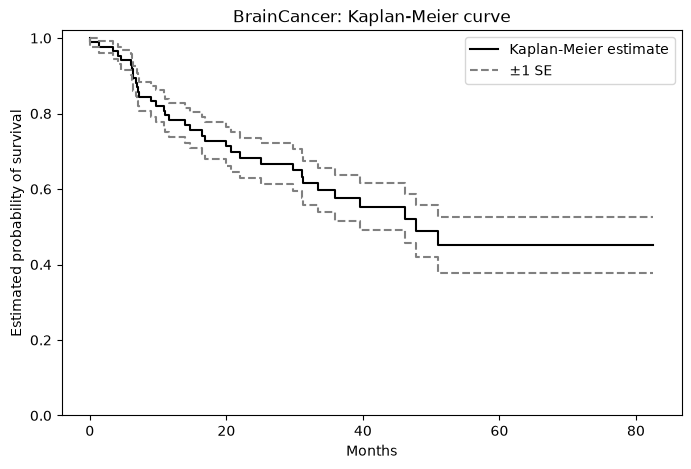

In [2]:
# Exercise 10(a)
BrainCancer = load_data("BrainCancer")
print(BrainCancer.shape)

km = KaplanMeierFitter().fit(BrainCancer["time"], BrainCancer["status"])
# Greenwood standard error: SE(S(t)) = S(t) * sqrt( sum_{t_j <= t} d_j / (n_j (n_j - d_j)) )
et = km.event_table
terms = np.where(et["at_risk"] > et["observed"],
                 et["observed"] / (et["at_risk"] * (et["at_risk"] - et["observed"])), 0.0)
greenwood_se = km.survival_function_["KM_estimate"] * np.sqrt(np.cumsum(terms))

S = km.survival_function_["KM_estimate"]
fig, ax = plt.subplots(figsize=(8, 5))
ax.step(S.index, S, where="post", color="black", label="Kaplan-Meier estimate")
ax.step(S.index, (S + greenwood_se).clip(upper=1), where="post", color="gray", ls="--", label="±1 SE")
ax.step(S.index, (S - greenwood_se).clip(lower=0), where="post", color="gray", ls="--")
ax.set(xlabel="Months", ylabel="Estimated probability of survival", title="BrainCancer: Kaplan-Meier curve", ylim=(0, 1.02))
ax.legend()
plt.show()

### Exercise 10(b)

Draw a bootstrap sample of size n = 88 from the pairs (yi, δi),
and compute the resulting Kaplan-Meier survival curve. Repeat
this process B = 200 times. Use the results to obtain an estimate
of the standard error of the Kaplan-Meier survival curve at each
timepoint. Compare this to the standard errors obtained in (a).

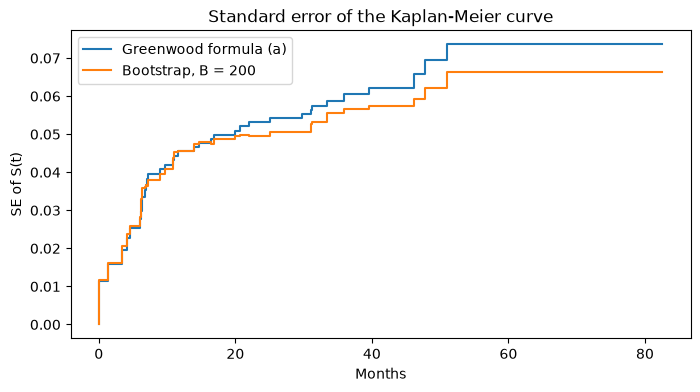

,S(t),Greenwood SE,bootstrap SE
month,,,
10,0.8206,0.0420,0.0408
20,0.7132,0.0509,0.0495
30,0.6503,0.0553,0.0507
40,0.5525,0.0623,0.0575
50,0.4892,0.0694,0.0621


In [3]:
# Exercise 10(b)
B = 200
timeline = S.index.to_numpy()
boot_curves = np.empty((B, len(timeline)))
n = len(BrainCancer)
for b in range(B):
    idx = rng.choice(n, n, replace=True)
    km_b = KaplanMeierFitter().fit(BrainCancer["time"].iloc[idx], BrainCancer["status"].iloc[idx])
    boot_curves[b] = km_b.survival_function_at_times(timeline).to_numpy()
boot_se = boot_curves.std(axis=0, ddof=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.step(timeline, greenwood_se, where="post", label="Greenwood formula (a)")
ax.step(timeline, boot_se, where="post", label=f"Bootstrap, B = {B}")
ax.set(xlabel="Months", ylabel="SE of S(t)", title="Standard error of the Kaplan-Meier curve")
ax.legend()
plt.show()

check_times = [10, 20, 30, 40, 50]
pd.DataFrame({
    "S(t)": km.survival_function_at_times(check_times).to_numpy(),
    "Greenwood SE": [greenwood_se[greenwood_se.index <= t].iloc[-1] for t in check_times],
    "bootstrap SE": [boot_se[timeline <= t][-1] for t in check_times],
}, index=pd.Index(check_times, name="month")).round(4)

### Exercise 10(c)

Fit a Cox proportional hazards model that uses all of the predictors to predict survival. Summarize the main findings.

In [4]:
# Exercise 10(c)
bc = BrainCancer.dropna().copy()          # one observation has a missing diagnosis
X_cox = pd.get_dummies(bc, columns=["sex", "diagnosis", "loc", "stereo"], drop_first=True, dtype=float)
cox_all = CoxPHFitter().fit(X_cox, duration_col="time", event_col="status")
cox_all.print_summary(decimals=3, columns=["coef", "exp(coef)", "se(coef)", "z", "p"])

<lifelines.CoxPHFitter: fitted with 87 total observations, 52 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 87
number of events observed = 35
   partial log-likelihood = -116.748
         time fit was run = 2026-10-21 06:48:20 UTC

---
                       coef exp(coef)  se(coef)      z       p
covariate                                                     
ki                   -0.055     0.947     0.018 -3.001   0.003
gtv                   0.034     1.035     0.022  1.536   0.125
sex_Male              0.184     1.202     0.360  0.510   0.610
diagnosis_LG glioma  -1.240     0.290     0.580 -2.139   0.032
diagnosis_Meningioma -2.155     0.116     0.451 -4.782 <0.0005
diagnosis_Other      -1.269     0.281     0.618 -2.054   0.040
loc_Supratentorial    0.441     1.555     0.704  0.627   0.531
stereo_SRT            0.178     1.195     0.602  0.296   0.768
---
Concordance = 0.794
Partial AIC = 249.495
log-likelihood ratio test = 41.372 on 8 df
-log2(p) of ll-ratio test = 19.103

### Exercise 10(d)

Stratify the data by the value of ki. (Since only one observation
has ki==40, you can group that observation together with the observations that have ki==60.) Plot Kaplan-Meier survival curves
for each of the five strata, adjusted for the other predictors.

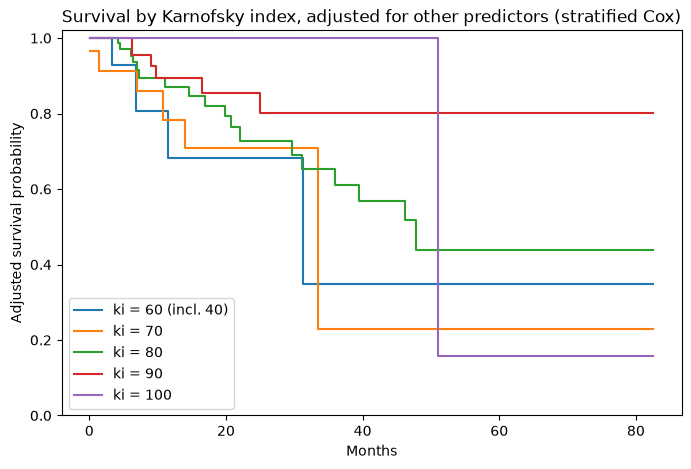

ki
60      6
70     14
80     36
90     26
100     5
Name: count, dtype: int64


In [5]:
# Exercise 10(d)
X_strat = X_cox.copy()
X_strat["ki"] = X_strat["ki"].replace(40, 60)            # merge the single ki = 40 case into ki = 60
cox_strat = CoxPHFitter().fit(X_strat, duration_col="time", event_col="status", strata=["ki"])

# Baseline survival per stratum = survival curve for a patient with the other predictors at their means
# (lifelines centres covariates), i.e. each curve is adjusted for the other predictors.
fig, ax = plt.subplots(figsize=(8, 5))
for stratum, curve in cox_strat.baseline_survival_.items():
    ax.step(curve.index, curve.values, where="post", label=f"ki = {stratum}" + (" (incl. 40)" if stratum == 60 else ""))
ax.set(xlabel="Months", ylabel="Adjusted survival probability",
       title="Survival by Karnofsky index, adjusted for other predictors (stratified Cox)", ylim=(0, 1.02))
ax.legend()
plt.show()
print(X_strat["ki"].value_counts().sort_index())

**Observations / conclusions**

- **(a)** Estimated survival falls to about 0.82 at 10 months, 0.65 at 30 months and 0.49 at 50 months. The ±1 SE (Greenwood) band widens over time as fewer patients remain at risk.
- **(b)** The bootstrap SEs (B = 200) closely track the Greenwood SEs: 0.041 vs 0.042 at 10 months, and 0.062 vs 0.069 at 50 months. The bootstrap values are slightly smaller at later times, but both methods give the same picture of uncertainty.
- **(c)** In the Cox model with all predictors (87 patients after dropping one missing diagnosis), the significant effects are **diagnosis** and the **Karnofsky index**. Compared with HG glioma, meningioma has a hazard ratio of 0.12 (p < 0.001), LG glioma 0.29 (p = 0.03), and other diagnoses 0.28 (p = 0.04). Each 1-point increase in `ki` multiplies the hazard by 0.947 (p = 0.003), so a 10-point increase reduces it by about 42%. Sex, tumour location, gross tumour volume and stereotactic method are not significant. Concordance is 0.79.
- **(d)** In the stratified Cox model, the adjusted survival curves are broadly ordered by `ki`: higher functional status means better survival. At 20 months the adjusted survival is 0.68, 0.71, 0.79, 0.85 and 1.00 for ki = 60, 70, 80, 90, 100. The 5 patients with ki = 100 had no deaths, so their curve stays at 1. The ki = 60 and 70 curves cross after about 30 months (the strata are small: 6 and 14 patients). Overall this matches the strong `ki` effect in (c).

---

## Exercise 11 · Applied

**Textbook: printed page 502**

This exercise makes use of the data in Table 11.4.

### Exercise 11(a)

Create two groups of observations. In Group 1, X < 2, whereas
in Group 2, X ≥2. Plot the Kaplan-Meier survival curves corresponding to the two groups. Be sure to label the curves so that
it is clear which curve corresponds to which group. By eye, does
there appear to be a difference between the two groups’ survival
curves?

,Y,delta,X,group
observation,,,,
1,26.5,1,0.1,1
2,37.2,1,11.0,2
3,57.3,1,-0.3,1
4,90.8,0,2.8,2
5,20.2,0,1.8,1
6,89.8,0,0.4,1


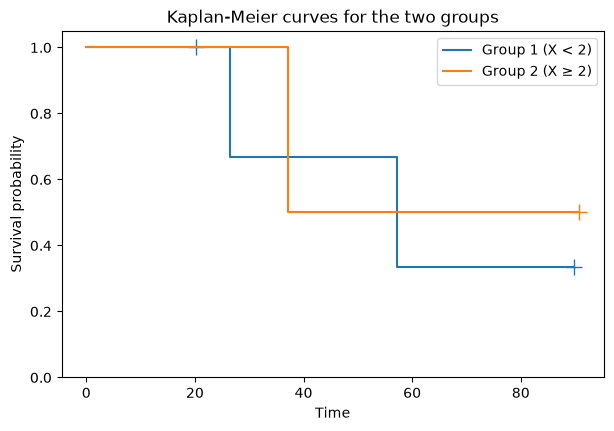

In [6]:
# Exercise 11(a)
# Table 11.4 (ISLP p. 502)
table_11_4 = pd.DataFrame({
    "Y": [26.5, 37.2, 57.3, 90.8, 20.2, 89.8],
    "delta": [1, 1, 1, 0, 0, 0],
    "X": [0.1, 11.0, -0.3, 2.8, 1.8, 0.4],
}, index=pd.RangeIndex(1, 7, name="observation"))
table_11_4["group"] = np.where(table_11_4["X"] < 2, 1, 2)
display(table_11_4)

fig, ax = plt.subplots(figsize=(7, 4.5))
for g, label in [(1, "Group 1 (X < 2)"), (2, "Group 2 (X ≥ 2)")]:
    d = table_11_4[table_11_4["group"] == g]
    KaplanMeierFitter(label=label).fit(d["Y"], d["delta"]).plot_survival_function(ax=ax, ci_show=False, show_censors=True)
ax.set(xlabel="Time", ylabel="Survival probability", title="Kaplan-Meier curves for the two groups", ylim=(0, 1.05))
plt.show()

### Exercise 11(b)

Fit Cox’s proportional hazards model, using the group indicator
as a covariate. What is the estimated coefficient? Write a sentence providing the interpretation of this coefficient, in terms
of the hazard or the instantaneous probability of the event. Is
there evidence that the true coefficient value is non-zero?

In [7]:
# Exercise 11(b)
cox_11 = CoxPHFitter().fit(table_11_4.assign(group2=(table_11_4["group"] == 2).astype(int))[["Y", "delta", "group2"]],
                          duration_col="Y", event_col="delta")
cox_11.print_summary(decimals=3, columns=["coef", "exp(coef)", "se(coef)", "z", "p"])
lr_test_cox = cox_11.log_likelihood_ratio_test()

<lifelines.CoxPHFitter: fitted with 6 total observations, 3 right-censored observations>
             duration col = 'Y'
                event col = 'delta'
      baseline estimation = breslow
   number of observations = 6
number of events observed = 3
   partial log-likelihood = -4.055
         time fit was run = 2026-10-21 06:48:20 UTC

---
            coef exp(coef)  se(coef)      z     p
covariate                                        
group2    -0.340     0.712     1.236 -0.275 0.783
---
Concordance = 0.556
Partial AIC = 10.110
log-likelihood ratio test = 0.078 on 1 df
-log2(p) of ll-ratio test = 0.359

### Exercise 11(c)

Recall from Section 11.5.2 that in the case of a single binary
covariate, the log-rank test statistic should be identical to the
score statistic for the Cox model. Conduct a log-rank test to determine whether there is a difference between the survival curves
for the two groups. How does the p-value for the log-rank test
statistic compare to the p-value for the score statistic for the
Cox model from (b)?

In [8]:
# Exercise 11(c)
g1, g2 = table_11_4[table_11_4["group"] == 1], table_11_4[table_11_4["group"] == 2]
lr = logrank_test(g1["Y"], g2["Y"], event_observed_A=g1["delta"], event_observed_B=g2["delta"])
print(f"Log-rank test: chi^2 = {lr.test_statistic:.4f}, p = {lr.p_value:.4f}")

# Cox score test at beta = 0, computed directly (lifelines reports Wald and LR tests, not the score test).
def cox_score_test(time, event, x):
    order = np.argsort(time)
    time, event, x = time[order], event[order], x[order]
    U = I = 0.0
    for i in np.where(event == 1)[0]:
        at_risk = time >= time[i]
        xbar = x[at_risk].mean()
        U += x[i] - xbar
        I += x[at_risk].var()          # population variance among those at risk
    stat = U**2 / I
    from scipy.stats import chi2
    return stat, chi2.sf(stat, df=1)

stat, p = cox_score_test(table_11_4["Y"].to_numpy(), table_11_4["delta"].to_numpy(),
                         (table_11_4["group"] == 2).astype(float).to_numpy())
print(f"Cox score test:  chi^2 = {stat:.4f}, p = {p:.4f}")
print(f"Cox Wald test p = {cox_11.summary.loc['group2', 'p']:.4f}; likelihood-ratio test p = {lr_test_cox.p_value:.4f}")

Log-rank test: chi^2 = 0.0764, p = 0.7822
Cox score test:  chi^2 = 0.0764, p = 0.7822
Cox Wald test p = 0.7831; likelihood-ratio test p = 0.7797


**Observations / conclusions**

- **(a)** Group 1 (X < 2) contains observations 1, 3, 5, 6, and Group 2 (X ≥ 2) contains 2 and 4. By eye the curves cross and look very similar. With only six observations, there is no visible difference.
- **(b)** The Cox coefficient for the Group 2 indicator is **−0.340** (hazard ratio 0.71). At any time, a member of Group 2 has an estimated instantaneous risk of the event about 29% lower than a member of Group 1. The standard error is 1.24 (p = 0.78), so there is **no evidence** that the true coefficient is non-zero.
- **(c)** The log-rank test gives χ² = 0.0764 and **p = 0.782**. The Cox *score* statistic, computed directly, is identical (χ² = 0.0764, p = 0.782), exactly as Section 11.5.2 says for a single binary covariate with no tied times. The Wald (p = 0.783) and likelihood-ratio (p = 0.780) tests are nearly the same.